<a href="https://colab.research.google.com/github/Izaias02/-ATV04PW2/blob/main/analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho Final — Análise de Dados e Regressão Linear no E-commerce

**Objetivo:** Entender o que faz o número de pedidos diários subir ou descer entre 2023 e 2025 e ver se dá para prever a demanda com base nisso.

---

## Parte 1 — Primeiro contato com a base
Começamos puxando a base direto do Google Drive para dar uma olhada geral no tamanho do arquivo e nas colunas disponíveis.

In [ ]:
from google.colab import drive
import numpy as np
import pandas as pd

# Conectando ao Drive
drive.mount('/content/drive', force_remount=True)

# Caminho exato confirmado
caminho_arquivo = '/content/drive/MyDrive/atividade final/base_projeto_prophet_ecommerce_(1).csv'

# Lendo a base de dados
df = pd.read_csv(caminho_arquivo)

# Visualizando as primeiras 5 linhas
df.head()

Mounted at /content/drive


,data,pedidos,evento
0,2023-01-01,375,Nenhum
1,2023-01-02,537,Campanha de Verão
2,2023-01-03,663,Campanha de Verão
3,2023-01-04,607,Campanha de Verão
4,2023-01-05,576,Campanha de Verão


In [ ]:
# a) e b) Número de linhas e colunas
linhas, colunas = df.shape
print(f'a) Número de linhas: {linhas}')
print(f'b) Número de colunas: {colunas}')

print('\nc) e d) Variáveis disponíveis e seus tipos originais:')
print(df.dtypes)

# e) Conversão da coluna 'data' para datetime
df['data'] = pd.to_datetime(df['data'])
print(f"\ne) Tipo da coluna 'data' após conversão: {df['data'].dtype}")

a) Número de linhas: 1096
b) Número de colunas: 3

c) e d) Variáveis disponíveis e seus tipos originais:
data       object
pedidos     int64
evento     object
dtype: object

e) Tipo da coluna 'data' após conversão: datetime64[ns]


### O que encontramos na estrutura dos dados (Item 1.1):

* **Tamanho do arquivo:** A base tem 1.096 linhas, onde cada linha é 1 dia de vendas da loja.
* **Colunas:** São 3 variáveis ao todo (`data`, `pedidos` e `evento`).
* **Tipos de dados:**
  * `data`: O Pandas leu primeiro como texto (`object`).
  * `pedidos`: Veio como número inteiro (`int64`).
  * `evento`: Veio como texto (`object`).
* **Ajuste na data:** Tivemos que converter a coluna `data` para o formato de data real (`datetime`). Fizemos isso porque só assim o Python consegue entender a ordem dos dias e tirar informações como o dia da semana.´~

In [ ]:
# 1.2 - Verificando valores ausentes e registros duplicados
print('--- Verificação de Qualidade ---')
print('Valores ausentes por coluna:\n', df.isnull().sum())
print('\nRegistros duplicados:', df.duplicated().sum())

# 1.3 - Identificando o período disponível
primeira_data = df['data'].min().strftime('%d/%m/%Y')
ultima_data = df['data'].max().strftime('%d/%m/%Y')

print('\n--- Período das Observações ---')
print(f'Primeira data disponível: {primeira_data}')
print(f'Última data disponível: {ultima_data}')

--- Verificação de Qualidade ---
Valores ausentes por coluna:
 data       0
pedidos    0
evento     0
dtype: int64

Registros duplicados: 0

--- Período das Observações ---
Primeira data disponível: 01/01/2023
Última data disponível: 31/12/2025


### Qualidade dos dados e datas da base (Itens 1.2 e 1.3):

* **Checagem de erros:**
  * Não encontramos nenhum valor em branco (nulo) e nem linhas repetidas.
  * Foi importante fazer essa checagem logo de cara porque se tivéssemos dados duplicados ou faltando, as médias e o cálculo da regressão ficariam errados.
* **Período da base:**
  * A base começa em **01/01/2023** e vai até **31/12/2025**. Ou seja, temos exatamente 3 anos de histórico para analisar.

## Parte 2 — Conhecendo a Variável 'pedidos'

Nesta seção, analisamos as medidas estatísticas de posição e dispersão para a variável dependente `pedidos`, que representa o volume diário de vendas do e-commerce.

In [ ]:
# 2.1 - Calculando estatísticas descritivas individuais
media = df["pedidos"].mean()
mediana = df["pedidos"].median()
desvio_padrao = df["pedidos"].std()
minimo = df["pedidos"].min()
maximo = df["pedidos"].max()
q1 = df["pedidos"].quantile(0.25)
q3 = df["pedidos"].quantile(0.75)

# Exibindo os resultados de forma organizada
print("--- Estatísticas Descritivas de Pedidos ---")
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio-Padrão: {desvio_padrao:.2f}")
print(f"Mínimo: {minimo}")
print(f"Primeiro Quartil (Q1 - 25%): {q1:.2f}")
print(f"Terceiro Quartil (Q3 - 75%): {q3:.2f}")
print(f"Máximo: {maximo}")

--- Estatísticas Descritivas de Pedidos ---
Média: 540.27
Mediana: 539.00
Desvio-Padrão: 93.79
Mínimo: 167
Primeiro Quartil (Q1 - 25%): 480.00
Terceiro Quartil (Q3 - 75%): 599.25
Máximo: 919


### Olhando de perto para a quantidade de pedidos (Item 2.1):

* **Média:** Fica em 540,27 pedidos por dia.
* **Mediana:** Fica em 539,00 pedidos por dia.
* **Média x Mediana:** As duas deram quase o mesmo valor (diferença de só 1 pedido), o que mostra que os dados estão bem equilibrados no meio.
* **Desvio-padrão:** Deu 93,79 pedidos. Isso significa que, no dia a dia, a demanda oscila uns 94 pedidos para cima ou para baixo em relação à média.
* **Mínimo e Máximo:** O pior dia teve 167 pedidos e o melhor teve 919 (uma variação bem grande, de 752 pedidos de diferença).
* **Quartis:** Em metade dos dias da base, as vendas ficaram ali na faixa "normal" entre 480 ($Q1$) e 600 ($Q3$) pedidos.

**O que isso significa na prática para o galpão/logística?**
Saber que a média é 540 pedidos ajuda a ter um norte, mas o desvio de 94 pedidos e os picos de mais de 900 mostram que a operação não pode trabalhar no limite exato da média. Se a equipe do galpão for dimensionada só para os 540 pedidos, nos dias de alta vai ter atraso na entrega e correria.

## Parte 3 — A Distribuição dos Pedidos

Para compreender visualmente a simetria dos dados, a concentração das vendas e a presença de valores extremos (*outliers*), construímos o histograma e o boxplot da variável `pedidos`.

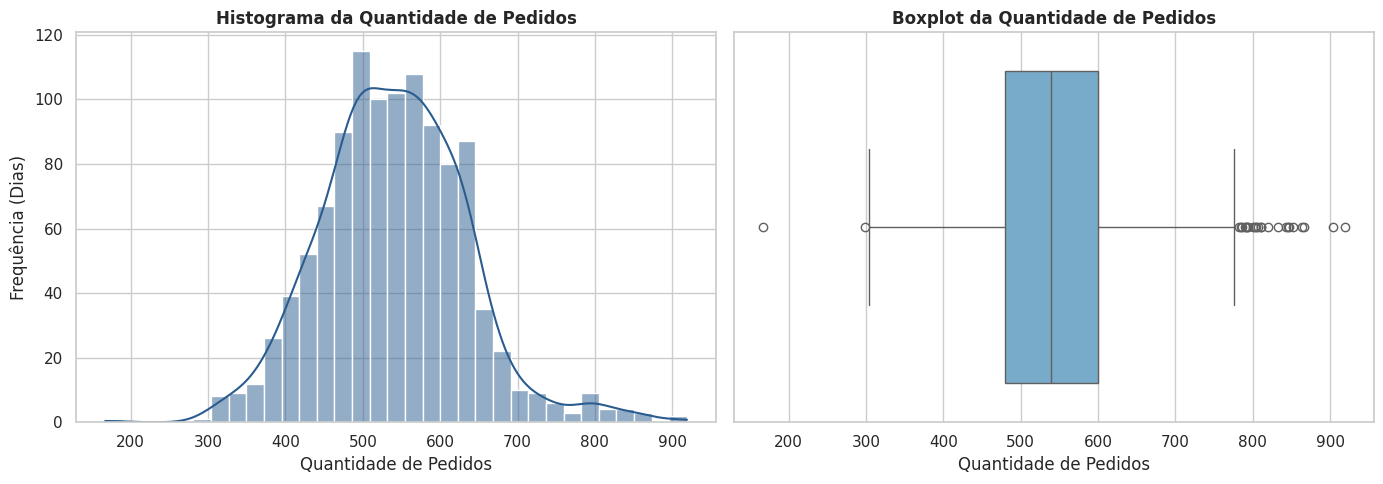

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual do Seaborn
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3.1 — Histograma da quantidade de pedidos
sns.histplot(df["pedidos"], kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title(
    "Histograma da Quantidade de Pedidos", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Quantidade de Pedidos")
axes[0].set_ylabel("Frequência (Dias)")

# 3.2 — Boxplot da quantidade de pedidos
sns.boxplot(x=df["pedidos"], ax=axes[1], color="#6baed6")
axes[1].set_title(
    "Boxplot da Quantidade de Pedidos", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Quantidade de Pedidos")

plt.tight_layout()
plt.show()

### Entendendo a distribuição com os gráficos (Itens 3.1 e 3.2):

* **Formato do histograma:** A maioria dos dias fica ali acumulada no meio, entre 450 e 650 pedidos, lembrando o formato de um sino.
* **Pontos fora da curva (Outliers):** O boxplot mostrou alguns pontos bem afastados, principalmente para cima (dias com mais de 780 pedidos) e um ponto isolado lá embaixo perto dos 167.
* **Isso é erro de digitação?**
  * Provavelmente não. No e-commerce, esses picos altos acontecem por causa de promoções e datas fortes tipo Black Friday e Natal. Já os dias com vendas muito baixas podem ter acontecido por alguma falha no site ou no sistema de pagamento que travou as compras por umas horas.

## Parte 4 — Análise dos Pedidos por Dia da Semana

Apesar de a média geral de pedidos ser ~540/dia, o comportamento dos consumidores pode mudar dependendo do dia da semana. Nesta seção, extraímos o dia da semana a partir da variável `data` para investigar possíveis padrões semanais.

,mean,median,std
dia_semana_pt,,,
Segunda-feira,563.554140,562.0,80.518225
Terça-feira,561.834395,565.0,80.161523
Quarta-feira,564.388535,566.0,81.834703
Quinta-feira,572.019231,561.0,88.580087
Sexta-feira,567.326923,560.0,80.347886
Sábado,475.833333,471.0,90.902488
Domingo,476.898089,467.0,90.466397


/tmp/ipykernel_1606/3556319379.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


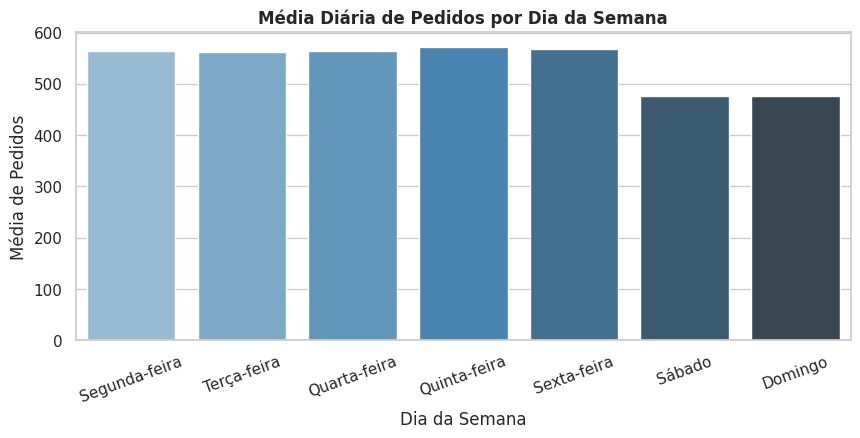

In [ ]:
# 4.1 - Extraindo o dia da semana numericamente (0 = Segunda, 6 = Domingo)
df['dia_semana_num'] = df['data'].dt.dayofweek

# Mapeando os nomes dos dias em português
dias_pt = {
    0: 'Segunda-feira',
    1: 'Terça-feira',
    2: 'Quarta-feira',
    3: 'Quinta-feira',
    4: 'Sexta-feira',
    5: 'Sábado',
    6: 'Domingo',
}
df['dia_semana_pt'] = df['dia_semana_num'].map(dias_pt)

# Calculando estatísticas agrupadas na ordem cronológica da semana
ordem_dias = [
    'Segunda-feira',
    'Terça-feira',
    'Quarta-feira',
    'Quinta-feira',
    'Sexta-feira',
    'Sábado',
    'Domingo',
]

pedidos_por_dia = (
    df.groupby('dia_semana_pt')['pedidos']
    .agg(['mean', 'median', 'std'])
    .reindex(ordem_dias)
)

display(pedidos_por_dia)

# Gráfico de barras
plt.figure(figsize=(10, 4))
sns.barplot(
    data=pedidos_por_dia.reset_index(),
    x='dia_semana_pt',
    y='mean',
    palette='Blues_d',
)
plt.title(
    'Média Diária de Pedidos por Dia da Semana', fontsize=12, fontweight='bold'
)
plt.xlabel('Dia da Semana')
plt.ylabel('Média de Pedidos')
plt.xticks(rotation=20)
plt.show()

### Comparando os dias da semana (Item 4.1):

* **Dia mais forte:** Quinta-feira (média de 572 pedidos).
* **Dia mais fraco:** Sábado (média de 475 pedidos).
* **O padrão da semana:** Durante os dias úteis (segunda a sexta), as vendas ficam bem firmes e quase iguais, na faixa de 560 a 570 pedidos. Mas no fim de semana a demanda cai bastante, ficando em cerca de 476 pedidos tanto no sábado quanto no domingo.

## Parte 5 — Comparação: Dias Úteis vs. Finais de Semana

Com base nos resultados da Parte 4, criamos uma variável binária chamada `fim_semana` para quantificar diretamente o impacto do final de semana sobre a quantidade diária de pedidos.

,count,mean,median,std
Grupo 1 — Dias Úteis (0),783,565.814815,562.0,82.211646
Grupo 2 — Finais de Semana (1),313,476.367412,470.0,90.540130


/tmp/ipykernel_1606/1516991547.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


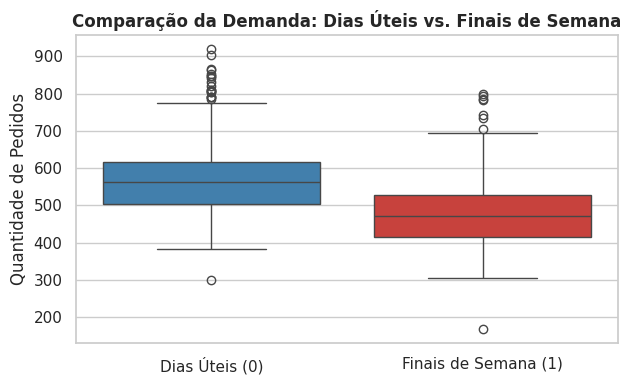

In [ ]:
# 5.1 — Criando a variável fim_semana (0 = Dia Útil, 1 = Fim de Semana)
df['fim_semana'] = df['dia_semana_num'].isin([5, 6]).astype(int)

# Separando e calculando medidas estatísticas para os grupos
estatisticas_fds = df.groupby('fim_semana')['pedidos'].agg(
    ['count', 'mean', 'median', 'std']
)
estatisticas_fds.index = ['Grupo 1 — Dias Úteis (0)', 'Grupo 2 — Finais de Semana (1)']

display(estatisticas_fds)

# Visualização gráfica comparativa (Boxplot)
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=df, x='fim_semana', y='pedidos', palette=['#3182bd', '#de2d26']
)
plt.xticks([0, 1], ['Dias Úteis (0)', 'Finais de Semana (1)'])
plt.title(
    'Comparação da Demanda: Dias Úteis vs. Finais de Semana',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('')
plt.ylabel('Quantidade de Pedidos')
plt.show()

### Comparando dias úteis com fim de semana (Item 5.1):

* **Diferença dos grupos:** Nos dias de semana a média é **565,81 pedidos**, e no fim de semana cai para **476,37 pedidos**.
* **Faz diferença na rotina?** Com certeza. É uma queda de quase 90 pedidos por dia no fim de semana (cerca de 15% a menos). Isso muda o planejamento de quantas pessoas precisam trabalhar na separação dos pacotes nesses dias.
* **Por que colocar isso no modelo?** Porque se não avisarmos ao modelo se o dia é fim de semana ou não, ele vai tentar adivinhar um valor do meio e vai errar todas as previsões de sábado e domingo para cima.

## Parte 6 — O Impacto dos Eventos Comerciais

Eventos promocionais (como Black Friday, Natal e campanhas sazonais) alteram o comportamento de compra dos consumidores. Nesta seção, analisamos a frequência dessas datas e criamos uma variável binária `tem_evento` para quantificar o seu efeito sobre as vendas.

--- Contagem de Dias por Tipo de Evento ---
evento
Nenhum                  1021
Natal                     27
Campanha de Verão         18
Semana do Consumidor      15
Black Friday              15
Name: count, dtype: int64


,count,mean,median,std
Grupo 1 — Sem Evento (0),1021,527.890304,531.0,81.027735
Grupo 2 — Com Evento (1),75,708.800000,714.0,93.620857


/tmp/ipykernel_1606/3619843136.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


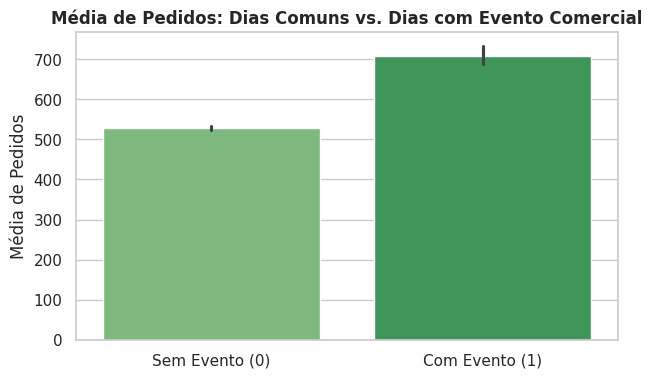

In [ ]:
# 6.1 — Frequência e tipos de eventos na base
print('--- Contagem de Dias por Tipo de Evento ---')
print(df['evento'].value_counts())

# 6.2 — Criando a variável indicadora tem_evento (0 = Sem Evento, 1 = Com Evento)
df['tem_evento'] = (df['evento'] != 'Nenhum').astype(int)

# Comparação estatística entre dias sem evento e dias com evento
estatisticas_evento = df.groupby('tem_evento')['pedidos'].agg(
    ['count', 'mean', 'median', 'std']
)
estatisticas_evento.index = [
    'Grupo 1 — Sem Evento (0)',
    'Grupo 2 — Com Evento (1)',
]

display(estatisticas_evento)

# Visualização gráfica comparativa (Gráfico de Barras)
plt.figure(figsize=(7, 4))
sns.barplot(
    data=df, x='tem_evento', y='pedidos', palette=['#74c476', '#31a354']
)
plt.xticks([0, 1], ['Sem Evento (0)', 'Com Evento (1)'])
plt.title(
    'Média de Pedidos: Dias Comuns vs. Dias com Evento Comercial',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('')
plt.ylabel('Média de Pedidos')
plt.show()

### O peso das datas comemorativas e eventos (Itens 6.1 e 6.2):

* **Dias com evento:** Dos 1.096 dias, 75 tiveram algum evento (Black Friday, Natal, Semana do Consumidor ou Campanha de Verão).
* **Comparação direta:**
  * **Dias sem evento:** Média de 527,89 pedidos.
  * **Dias com evento:** Média de 708,80 pedidos.
* **Conclusão:** Um dia com evento vende, em média, **180 pedidos a mais (+34%)** do que um dia comum. É essa variável que explica aqueles picos que tínhamos visto como *outliers* no gráfico do boxplot.

## Partes 7 e 8 — Evolução Temporal e Correlação de Pearson

Para avaliar se existe uma tendência de crescimento do e-commerce ao longo dos anos (2023 a 2025), transformamos a data numa variável numérica `tempo` (dias decorridos a partir do dia 0) e calculamos o Coeficiente de Correlação de Pearson entre o tempo e a quantidade de pedidos.

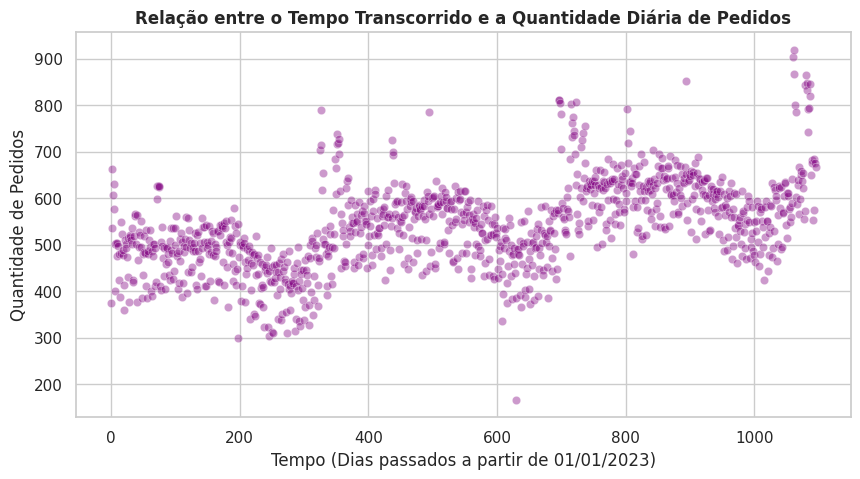

Coeficiente de Correlação de Pearson (Tempo x Pedidos): 0.5236


In [ ]:
# Parte 7 — Criando a variável numérica tempo (dias decorridos a partir da primeira data)
df['tempo'] = (df['data'] - df['data'].min()).dt.days

# Visualização gráfica: Eixo X = tempo, Eixo Y = pedidos
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='tempo', y='pedidos', alpha=0.4, color='purple')
plt.title(
    'Relação entre o Tempo Transcorrido e a Quantidade Diária de Pedidos',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tempo (Dias passados a partir de 01/01/2023)')
plt.ylabel('Quantidade de Pedidos')
plt.show()

# Parte 8 — Calculando a Correlação de Pearson
correlacao = df['tempo'].corr(df['pedidos'])
print(f'Coeficiente de Correlação de Pearson (Tempo x Pedidos): {correlacao:.4f}')

### O crescimento no tempo e a correlação (Itens 7.1 e 8.1):

* **O que vemos no gráfico:** No gráfico de pontos dá para notar claramente que, conforme os dias passam, os pontos vão subindo. Ou seja, a loja está vendendo mais com o passar dos meses.
* **Correlação de Pearson:** Deu **0,5236**.
* **O que isso mostra:** É uma correlação positiva moderada. Ela confirma em número o que vimos na imagem: existe uma tendência real de crescimento da empresa ao longo desses três anos.

## Partes 9 e 10 — Ajuste da Regressão Linear Simples e Visualização da Reta

Ajustamos o nosso primeiro modelo de regressão linear considerando a variável `tempo` como variável explicativa ($X$) e a variável `pedidos` como variável resposta ($y$).

**negrito**

---



Intercepto (Beta 0): 455.3237
Coeficiente do Tempo (Beta 1): 0.1552
R-quadrado (R²): 0.2742


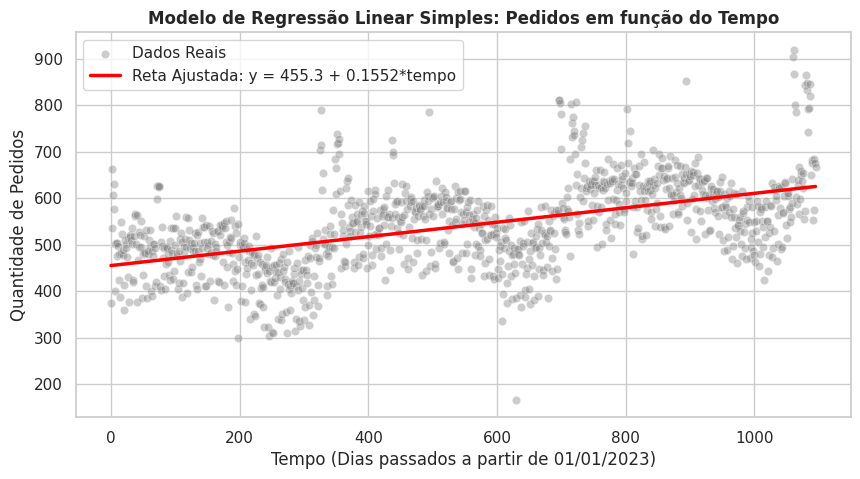

In [ ]:
import statsmodels.api as sm

# Parte 9 — Ajustando a Regressão Linear Simples
X = sm.add_constant(df['tempo'])  # Adiciona o intercepto
y = df['pedidos']

modelo_simples = sm.OLS(y, X).fit()

# Extraindo os coeficientes
intercepto = modelo_simples.params['const']
coef_tempo = modelo_simples.params['tempo']
r2 = modelo_simples.rsquared

print(f'Intercepto (Beta 0): {intercepto:.4f}')
print(f'Coeficiente do Tempo (Beta 1): {coef_tempo:.4f}')
print(f'R-quadrado (R²): {r2:.4f}')

# Parte 10 — Visualizando o Gráfico com a Reta de Regressão
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x='tempo',
    y='pedidos',
    alpha=0.4,
    color='gray',
    label='Dados Reais',
)
plt.plot(
    df['tempo'],
    modelo_simples.predict(X),
    color='red',
    linewidth=2.5,
    label=f'Reta Ajustada: y = {intercepto:.1f} + {coef_tempo:.4f}*tempo',
)
plt.title(
    'Modelo de Regressão Linear Simples: Pedidos em função do Tempo',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Tempo (Dias passados a partir de 01/01/2023)')
plt.ylabel('Quantidade de Pedidos')
plt.legend()
plt.show()

### Testando nossa primeira regressão linear (Itens 9.1 e 10.1):

* **Equação da reta:** $\text{Pedidos} = 455,32 + 0,1552 \times \text{tempo}$
* **O que os números dizem:**
  * **455,32 (Intercepto):** É o ponto de partida do modelo lá no primeiro dia da base (início de 2023).
  * **0,1552 (Inclinação):** Mostra que a empresa ganha, em média, **+0,15 pedido a cada dia que passa** (o que dá uns 4,6 pedidos a mais por mês).
* **Olhando para a reta vermelha:** A reta mostra certinho a direção do crescimento de longo prazo, mas erra bastante no dia a dia porque ignora o efeito dos finais de semana e das datas de promoção.

## Parte 11 — Avaliação do Modelo Simples e Conclusão Executiva

Avaliamos a capacidade explicativa do modelo de regressão linear simples através do Coeficiente de Determinação ($R^2$) e consolidamos os aprendizados para a tomada de decisão logística.

In [ ]:
# 11.1 - Métrica de Qualidade do Ajuste (R²)
r2_porcentagem = r2 * 100

print(f'Coeficiente de Determinação (R²): {r2:.4f}')
print(
    f'Percentual da variação explicada pelo tempo: {r2_porcentagem:.2f}%'
)

Coeficiente de Determinação (R²): 0.2742
Percentual da variação explicada pelo tempo: 27.42%


### Avaliando o $R^2$ e conclusões do projeto (Item 11.1):

* **Resultado do $R^2$:** Deu **0,2741 (27,41%)**.
* **O que isso significa:** Que o tempo sozinho só consegue explicar 27,4% das variações nos pedidos. O resto da oscilação diária (mais de 72%) depende de outras coisas.
* **Por que o $R^2$ deu 27% se a correlação foi 0,52?** Porque o $R^2$ é o quadrado da correlação ($0,5236^2 \approx 0,2741$). Isso prova que não dá para prever a demanda diária usando só o tempo.

**Resumo final:**
1. A loja vem crescendo de forma constante ao longo dos 3 anos.
2. A demanda muda bastante no fim de semana (vende menos) e em dias de eventos (vende muito mais).





3. **Recomendação:** Para o modelo ficar bom mesmo para a equipe de logística usar, o próximo passo é juntar o `tempo`, o `fim_semana` e o `tem_evento` numa **regressão múltipla**.